**Context for Final Project**

Time series complexity for the detection of life and technology. 

This project is an extension of the ‘Time Series Challenge” homework task. You will gather and analyze time series from different sources, ideally representative of the following categories: abiotic, biotic, technological. You will then use methods of your choice to process and estimate the complexities and information contents of these time series. You may find that complexity correlates with the presence of life/technology and you may also find false positives/false negatives. Any of the above outcomes are perfectly valid, as long as the methods have been consistently applied to the time series comparison. We can offer help as regards complexity and information metrics as well as data processing and potential sources for time series data. The broad goal of the project is to find robust methods that can distinguish biotic and technological signals from abiotic signals. You may also analyze non-time series data if you prefer, this could be sequences of DNA bases or sequences of amino acids in proteins, for example.

**General Idea**

* In HW5, we defined complexity ourselves through a set of metrics (entropy, compression, etc.), so we now let the model learn its own notion
* We learn some mapping from time series to embedding vector
  * Contrastive learning, so similar signals (like two segments of the same heartbeat dataset) should be close in latent space while different signals (like heartbeat vs. earthquake) should be farther apart
* For the model, we can use 1D CNN, transformer, temporal convolutional network (can try a few...)
* Then, visualize with PCA/t-SNE/UMAP to see if abiotic/biotic/techno signals occupy similar regions of the space

I think we can cherrypick some data sources that have similar features (so that the latent representation should look good). Brainstormed a list below, feel free to add/remove literally anything:

Abiotic

* Solar flares
* River flow
* Global temperature
* Earthquake seismogram

Biotic
* Heart rate
* Respiration
* EEG
* Sleep cycle

Techno
* Morse code
* GPS timeing
* Satellite telemetry
* Internet packet traffic

Progress
* Did a quick proof of concept with ~7 of the sources, focused on the abiotic/biotic ones to get started (no techno yet)
  * TODO: would be nice to add some more sources to fill it in (extend to techno, supplement the others). left a note at the bottom about syntax to do that.
* Set up a very pipeline (generate dataset --> train a very simple model --> visualize the embedding space)
  * TODO: should probably check on the actual dataset generation to see if it looks good, maybe need to augment more
  * TODO: should try fancier models like the ones above (or anything else), train for way more epochs than my 20
  * TODO: figure out best way to visualize data out of the ways above. should be quick, just quick visual inspection

In [29]:
#pip install -q numpy pandas scipy dataretrieval obspy wfdb mne scikit-learn requests

from __future__ import annotations

import json
import random
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Callable, Dict, Iterable, List, Optional

import numpy as np
import pandas as pd

random.seed(77)
np.random.seed(77)
RNG = np.random.default_rng(77)

In [30]:
@dataclass
class PipelineConfig:
    project_root: Path
    dataset_name: str = 'first_pass_v1'
    window_size: int = 256
    stride: int = 128
    detrend: bool = False
    save_raw_windows: bool = True
    max_windows_per_signal: Optional[int] = 2000
    min_valid_window_fraction: float = 0.95

    # Time bounds for downloadable sources
    start_date: str = '2018-01-01'
    end_date: str = '2024-12-31'

    # URLs
    goes_xray_url: str = 'https://services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json'
    global_temp_url: str = 'https://raw.githubusercontent.com/datasets/global-temp/master/data/monthly.csv'

    # Source-specific knobs
    river_sites: List[str] = field(default_factory=lambda: ['01646500', '02035000'])
    earthquake_requests: List[Dict[str, str]] = field(default_factory=lambda: [
        {
            'network': 'IU',
            'station': 'ANMO',
            'location': '00',
            'channel': 'BHZ',
            'start': '2019-01-01T00:00:00',
            'end': '2019-01-01T03:00:00',
        },
        {
            'network': 'IU',
            'station': 'COR',
            'location': '00',
            'channel': 'BHZ',
            'start': '2019-01-02T00:00:00',
            'end': '2019-01-02T03:00:00',
        },
    ])
    heart_records: List[str] = field(default_factory=lambda: ['100', '101', '103'])
    respiration_records: List[str] = field(default_factory=lambda: ['bidmc01', 'bidmc02'])
    eeg_records_limit: int = 3
    max_record_samples: Optional[int] = 200000

    # Morse synthesis
    morse_messages: List[str] = field(default_factory=lambda: [
        'AY159 FINAL PROJECT',
        'HELLO FROM TECHNOLOGY',
        'SIGNAL COMPLEXITY PIPELINE',
    ])
    morse_sample_rate: int = 100
    morse_wpm: float = 16.0

    @property
    def dataset_root(self) -> Path:
        return self.project_root / 'data' / self.dataset_name

    @property
    def standardized_root(self) -> Path:
        return self.dataset_root / 'standardized'

    @property
    def raw_root(self) -> Path:
        return self.dataset_root / 'raw'

    @property
    def metadata_csv(self) -> Path:
        return self.dataset_root / 'metadata.csv'

    @property
    def config_json(self) -> Path:
        return self.dataset_root / 'pipeline_config.json'


config = PipelineConfig(project_root=Path.cwd())
print(f'Dataset root: {config.dataset_root}')

Dataset root: /Users/rupalibatta/Downloads/data/first_pass_v1


In [31]:
def optional_import(module_name: str):
    try:
        module = __import__(module_name)
        return module
    except Exception:
        return None


def sanitize_token(text: str) -> str:
    valid = [c if c.isalnum() or c in ('-', '_', '.') else '_' for c in str(text)]
    return ''.join(valid).strip('_') or 'unknown'


def estimate_sampling_rate_from_time_index(index: pd.Index, default: float = 1.0) -> float:
    if len(index) < 2:
        return default
    dt = pd.Series(index).diff().dropna().dt.total_seconds().to_numpy()
    dt = dt[np.isfinite(dt) & (dt > 0)]
    if len(dt) == 0:
        return default
    return float(1.0 / np.median(dt))


def clean_series(x: np.ndarray, detrend: bool = False) -> np.ndarray:
    x = np.asarray(x, dtype=float).reshape(-1)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return x
    if detrend:
        scipy = optional_import('scipy')
        if scipy is not None:
            from scipy import signal
            x = signal.detrend(x)
        else:
            t = np.arange(len(x), dtype=float)
            p = np.polyfit(t, x, 1)
            x = x - (p[0] * t + p[1])
    return x


def zscore_window(w: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    mu = float(np.mean(w))
    sigma = float(np.std(w))
    if sigma < eps:
        return np.zeros_like(w)
    return (w - mu) / sigma


def segment_series(x: np.ndarray, window_size: int, stride: int) -> np.ndarray:
    if len(x) < window_size:
        return np.empty((0, window_size), dtype=float)
    windows = []
    for start in range(0, len(x) - window_size + 1, stride):
        windows.append(x[start:start + window_size])
    if not windows:
        return np.empty((0, window_size), dtype=float)
    return np.vstack(windows)


def assign_record_splits_grouped(
    record_keys: List[tuple],
    class_labels: List[str],
    train_frac: float = 0.7,
    val_frac: float = 0.15,
    random_state: int = 77,
) -> Dict[tuple, str]:
    """
    Assign each record (group) to train/val/test using grouped splitting.
    record_keys: list of (signal_name, source_id, record_id) per record.
    class_labels: class_label for each record (for stratification).
    Returns dict mapping record_key -> 'train'|'val'|'test'.
    """
    from sklearn.model_selection import train_test_split

    n = len(record_keys)
    if n == 0:
        return {}
    indices = np.arange(n)
    keys_arr = np.asarray(record_keys, dtype=object)
    y = np.asarray(class_labels)

    try:
        i_train, i_temp = train_test_split(
            indices, train_size=train_frac, stratify=y, random_state=random_state
        )
    except ValueError:
        i_train, i_temp = train_test_split(
            indices, train_size=train_frac, random_state=random_state
        )

    y_temp = y[i_temp]
    test_frac = 1.0 - train_frac - val_frac
    val_ratio = val_frac / (val_frac + test_frac) if (val_frac + test_frac) > 0 else 0.5
    try:
        i_val, i_test = train_test_split(
            i_temp, train_size=val_ratio, stratify=y_temp, random_state=random_state
        )
    except ValueError:
        i_val, i_test = train_test_split(
            i_temp, train_size=val_ratio, random_state=random_state
        )

    out = {}
    for i in i_train:
        out[record_keys[i]] = 'train'
    for i in i_val:
        out[record_keys[i]] = 'val'
    for i in i_test:
        out[record_keys[i]] = 'test'

    if len(i_val) == 0 or len(i_test) == 0:
        raise RuntimeError(
            'Grouped split produced an empty val or test set. '
            'Need more records or relax stratification.'
        )
    return out



In [32]:
@dataclass
class SignalRecord:
    signal_name: str
    class_label: str
    source_id: str
    sampling_rate: float
    values: np.ndarray
    record_id: str
    is_synthetic: bool = False


CLASS_MAP = {
    'abiotic': 0,
    'biotic': 1,
    'technological': 2,
}


In [33]:
def fetch_solar_flares(cfg: PipelineConfig) -> List[SignalRecord]:
    df = pd.read_json(cfg.goes_xray_url)
    if 'energy' in df.columns:
        df = df[df['energy'].astype(str).str.contains('0.1-0.8', na=False)]
    if 'flux' not in df.columns:
        raise ValueError('GOES response missing flux column.')
    if 'time_tag' in df.columns:
        ts = pd.to_datetime(df['time_tag'], errors='coerce')
        fs = estimate_sampling_rate_from_time_index(ts, default=1 / 60)
    else:
        fs = 1 / 60
    x = df['flux'].to_numpy(dtype=float)
    return [
        SignalRecord(
            signal_name='solar_flares',
            class_label='abiotic',
            source_id='noaa_goes_xray',
            sampling_rate=float(fs),
            values=x,
            record_id='goes_primary_7day',
            is_synthetic=False,
        )
    ]


def fetch_river_flow(cfg: PipelineConfig) -> List[SignalRecord]:
    dr = optional_import('dataretrieval')
    if dr is None:
        raise ImportError('dataretrieval is not installed.')
    import dataretrieval.nwis as nwis

    records: List[SignalRecord] = []
    for site in cfg.river_sites:
        frame = nwis.get_record(
            sites=site,
            service='iv',
            parameterCd='00060',
            start=cfg.start_date,
            end=cfg.end_date,
        )
        if frame is None or len(frame) == 0:
            continue
        value_cols = [c for c in frame.columns if '00060' in str(c)]
        if not value_cols:
            numeric_cols = [c for c in frame.columns if pd.api.types.is_numeric_dtype(frame[c])]
            if not numeric_cols:
                continue
            value_col = numeric_cols[0]
        else:
            value_col = value_cols[0]

        idx = pd.to_datetime(frame.index, errors='coerce')
        fs = estimate_sampling_rate_from_time_index(idx, default=1 / 900)
        values = frame[value_col].to_numpy(dtype=float)

        records.append(
            SignalRecord(
                signal_name='river_flow',
                class_label='abiotic',
                source_id=f'usgs_{site}',
                sampling_rate=float(fs),
                values=values,
                record_id=str(site),
                is_synthetic=False,
            )
        )
    if not records:
        raise ValueError('No river flow records retrieved.')
    return records


def fetch_global_temperature(cfg: PipelineConfig) -> List[SignalRecord]:
    df = pd.read_csv(cfg.global_temp_url)
    monthly_default_fs = 1 / (30 * 24 * 3600)

    if {'Source', 'Year', 'Mean'}.issubset(df.columns):
        ts = pd.to_datetime(df['Year'].astype(str), errors='coerce')
        values = pd.to_numeric(df['Mean'], errors='coerce').to_numpy(dtype=float)
        fs = estimate_sampling_rate_from_time_index(ts, default=monthly_default_fs)
        source_name = 'datasets_global_temp_monthly'
    elif {'Year', 'Month', 'Mean'}.issubset(df.columns):
        ts = pd.to_datetime(dict(year=df['Year'], month=df['Month'], day=1), errors='coerce')
        values = pd.to_numeric(df['Mean'], errors='coerce').to_numpy(dtype=float)
        fs = estimate_sampling_rate_from_time_index(ts, default=monthly_default_fs)
        source_name = 'nasa_gistemp_datahub'
    else:
        month_cols = [m for m in ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'] if m in df.columns]
        if 'Year' not in df.columns or len(month_cols) != 12:
            raise ValueError('Global temperature schema not recognized.')
        melted = df.melt(id_vars=['Year'], value_vars=month_cols, var_name='Month', value_name='Temp')
        month_num = {m: i + 1 for i, m in enumerate(month_cols)}
        melted['MonthNum'] = melted['Month'].map(month_num)
        melted['Date'] = pd.to_datetime(dict(year=melted['Year'], month=melted['MonthNum'], day=1), errors='coerce')
        melted = melted.sort_values('Date')
        values = pd.to_numeric(melted['Temp'], errors='coerce').to_numpy(dtype=float)
        fs = estimate_sampling_rate_from_time_index(melted['Date'], default=monthly_default_fs)
        source_name = 'nasa_gistemp_table'

    return [
        SignalRecord(
            signal_name='global_temperature',
            class_label='abiotic',
            source_id=source_name,
            sampling_rate=float(fs),
            values=values,
            record_id='global_monthly',
            is_synthetic=False,
        )
    ]


def fetch_earthquake_seismograms(cfg: PipelineConfig) -> List[SignalRecord]:
    obspy = optional_import('obspy')
    if obspy is None:
        raise ImportError('obspy is not installed.')

    from obspy import UTCDateTime
    from obspy.clients.fdsn import Client

    client = Client('IRIS')
    records: List[SignalRecord] = []

    for req in cfg.earthquake_requests:
        st = client.get_waveforms(
            network=req['network'],
            station=req['station'],
            location=req['location'],
            channel=req['channel'],
            starttime=UTCDateTime(req['start']),
            endtime=UTCDateTime(req['end']),
        )
        if len(st) == 0:
            continue
        tr = st[0]
        records.append(
            SignalRecord(
                signal_name='earthquake_seismogram',
                class_label='abiotic',
                source_id=f"iris_{req['network']}.{req['station']}.{req['channel']}",
                sampling_rate=float(tr.stats.sampling_rate),
                values=np.asarray(tr.data, dtype=float),
                record_id=f"{req['start']}_{req['end']}",
                is_synthetic=False,
            )
        )
    if not records:
        raise ValueError('No earthquake waveforms retrieved.')
    return records



In [34]:
def _wfdb_rdrecord_safe(wfdb, record_name: str, pn_dir: str, sampto: Optional[int]):
    if sampto is None:
        return wfdb.rdrecord(record_name, pn_dir=pn_dir)
    try:
        return wfdb.rdrecord(record_name, pn_dir=pn_dir, sampto=sampto)
    except ValueError as exc:
        if 'sampto must be shorter than the signal length' in str(exc):
            return wfdb.rdrecord(record_name, pn_dir=pn_dir)
        raise


def _wfdb_rdann_safe(wfdb, record_name: str, extension: str, pn_dir: str, sampto: Optional[int]):
    if sampto is None:
        return wfdb.rdann(record_name, extension, pn_dir=pn_dir)
    try:
        return wfdb.rdann(record_name, extension, pn_dir=pn_dir, sampto=sampto)
    except ValueError as exc:
        if 'sampto must be shorter than the signal length' in str(exc):
            return wfdb.rdann(record_name, extension, pn_dir=pn_dir)
        raise


def fetch_heart_rate(cfg: PipelineConfig) -> List[SignalRecord]:
    wfdb = optional_import('wfdb')
    if wfdb is None:
        raise ImportError('wfdb is not installed.')

    records: List[SignalRecord] = []
    for rec in cfg.heart_records:
        record = _wfdb_rdrecord_safe(wfdb, rec, pn_dir='mitdb', sampto=cfg.max_record_samples)
        ann = _wfdb_rdann_safe(wfdb, rec, 'atr', pn_dir='mitdb', sampto=cfg.max_record_samples)

        r = np.asarray(ann.sample, dtype=float)
        rr = np.diff(r) / float(record.fs)
        rr = rr[np.isfinite(rr) & (rr > 0)]
        if len(rr) < 10:
            continue

        hr = 60.0 / rr
        fs_hr = float(1.0 / np.median(rr))

        records.append(
            SignalRecord(
                signal_name='heart_rate',
                class_label='biotic',
                source_id=f'physionet_mitdb_{rec}',
                sampling_rate=fs_hr,
                values=hr,
                record_id=rec,
                is_synthetic=False,
            )
        )

    if not records:
        raise ValueError('No heart-rate records retrieved.')
    return records


def fetch_respiration(cfg: PipelineConfig) -> List[SignalRecord]:
    wfdb = optional_import('wfdb')
    if wfdb is None:
        raise ImportError('wfdb is not installed.')

    records: List[SignalRecord] = []
    for rec in cfg.respiration_records:
        r = _wfdb_rdrecord_safe(wfdb, rec, pn_dir='bidmc', sampto=cfg.max_record_samples)
        names = [str(s).upper() for s in r.sig_name]
        idx = next((i for i, n in enumerate(names) if 'RESP' in n), 0)
        x = np.asarray(r.p_signal[:, idx], dtype=float)

        records.append(
            SignalRecord(
                signal_name='respiration',
                class_label='biotic',
                source_id=f'physionet_bidmc_{rec}',
                sampling_rate=float(r.fs),
                values=x,
                record_id=rec,
                is_synthetic=False,
            )
        )

    if not records:
        raise ValueError('No respiration records retrieved.')
    return records


def fetch_eeg(cfg: PipelineConfig) -> List[SignalRecord]:
    mne = optional_import('mne')
    if mne is None:
        raise ImportError('mne is not installed.')

    # EEG Motor Movement/Imagery data from PhysioNet via MNE helpers (EDF files).
    from mne.datasets import eegbci

    runs = [1, 2, 3]
    eeg_cache = cfg.project_root / 'data' / 'eeg_cache'
    eeg_cache.mkdir(parents=True, exist_ok=True)
    files = eegbci.load_data(subjects=[1], runs=runs, path=str(eeg_cache), update_path=False)
    if not files:
        raise ValueError('No EEG EDF files retrieved from eegbci.')

    chosen = files[: cfg.eeg_records_limit]
    records: List[SignalRecord] = []

    for path in chosen:
        raw = mne.io.read_raw_edf(path, preload=False, verbose='ERROR')
        n_total = raw.n_times
        stop = n_total if cfg.max_record_samples is None else min(cfg.max_record_samples, n_total)
        x = raw.get_data(picks=[0], start=0, stop=stop, verbose='ERROR')[0]

        records.append(
            SignalRecord(
                signal_name='eeg',
                class_label='biotic',
                source_id='physionet_eegmmidb',
                sampling_rate=float(raw.info['sfreq']),
                values=np.asarray(x, dtype=float),
                record_id=sanitize_token(Path(path).stem),
                is_synthetic=False,
            )
        )

    if not records:
        raise ValueError('No EEG records retrieved.')
    return records


def text_to_morse_wave(message: str, fs: int, wpm: float) -> np.ndarray:
    morse_map = {
        'A': '.-', 'B': '-...', 'C': '-.-.', 'D': '-..', 'E': '.', 'F': '..-.',
        'G': '--.', 'H': '....', 'I': '..', 'J': '.---', 'K': '-.-', 'L': '.-..',
        'M': '--', 'N': '-.', 'O': '---', 'P': '.--.', 'Q': '--.-', 'R': '.-.',
        'S': '...', 'T': '-', 'U': '..-', 'V': '...-', 'W': '.--', 'X': '-..-',
        'Y': '-.--', 'Z': '--..',
        '0': '-----', '1': '.----', '2': '..---', '3': '...--', '4': '....-',
        '5': '.....', '6': '-....', '7': '--...', '8': '---..', '9': '----.',
    }

    dot_seconds = 1.2 / float(wpm)
    dot_n = max(1, int(round(dot_seconds * fs)))

    def tone(n: int) -> np.ndarray:
        t = np.arange(n) / fs
        return np.sin(2 * np.pi * 6.0 * t)

    parts = []
    words = message.upper().split(' ')
    for wi, word in enumerate(words):
        for ci, ch in enumerate(word):
            code = morse_map.get(ch)
            if code is None:
                continue
            for si, symbol in enumerate(code):
                n = dot_n if symbol == '.' else 3 * dot_n
                parts.append(tone(n))
                if si < len(code) - 1:
                    parts.append(np.zeros(dot_n))
            if ci < len(word) - 1:
                parts.append(np.zeros(3 * dot_n))
        if wi < len(words) - 1:
            parts.append(np.zeros(7 * dot_n))

    if not parts:
        return np.zeros(dot_n)
    y = np.concatenate(parts)
    y = y + 0.02 * RNG.standard_normal(len(y))
    return y


def fetch_morse(cfg: PipelineConfig) -> List[SignalRecord]:
    records: List[SignalRecord] = []
    for i, msg in enumerate(cfg.morse_messages):
        y = text_to_morse_wave(msg, fs=cfg.morse_sample_rate, wpm=cfg.morse_wpm)
        records.append(
            SignalRecord(
                signal_name='morse_code',
                class_label='technological',
                source_id='synthetic_morse',
                sampling_rate=float(cfg.morse_sample_rate),
                values=y,
                record_id=f'morse_{i:02d}',
                is_synthetic=True,
            )
        )
    return records





In [35]:
SIGNAL_SPECS = [
    {'signal_name': 'solar_flares', 'class_label': 'abiotic', 'fetch_fn': fetch_solar_flares},
    {'signal_name': 'river_flow', 'class_label': 'abiotic', 'fetch_fn': fetch_river_flow},
    {'signal_name': 'global_temperature', 'class_label': 'abiotic', 'fetch_fn': fetch_global_temperature},
    {'signal_name': 'earthquake_seismogram', 'class_label': 'abiotic', 'fetch_fn': fetch_earthquake_seismograms},
    {'signal_name': 'heart_rate', 'class_label': 'biotic', 'fetch_fn': fetch_heart_rate},
    {'signal_name': 'respiration', 'class_label': 'biotic', 'fetch_fn': fetch_respiration},
    {'signal_name': 'eeg', 'class_label': 'biotic', 'fetch_fn': fetch_eeg},
    {'signal_name': 'morse_code', 'class_label': 'technological', 'fetch_fn': fetch_morse},
]


In [36]:
# Technology data: RF comms, NAB telemetry, DCASE machine acoustics
# Adapted for notebook SignalRecord(sampling_rate=..., no meta)

from __future__ import annotations
import re
import math
import zipfile
import pathlib
import requests
from typing import Optional

import numpy as np
import pandas as pd
from scipy.io import wavfile
from scipy import signal as scipy_signal

TECH_ROOT = pathlib.Path("technology_data")
NAB_ROOT = TECH_ROOT / "nab"
DCASE_ROOT = TECH_ROOT / "dcase2020"
RADIOML_ROOT = TECH_ROOT / "radioml"
TECH_ROOT.mkdir(exist_ok=True, parents=True)
NAB_ROOT.mkdir(exist_ok=True, parents=True)
DCASE_ROOT.mkdir(exist_ok=True, parents=True)
HTTP_TIMEOUT = 60
CHUNK_SIZE = 1 << 20

def _safe_mkdir(path):
    path.mkdir(exist_ok=True, parents=True)
    return path

def _stream_download(url: str, dst, overwrite: bool = False):
    if dst.exists() and not overwrite:
        return dst
    dst.parent.mkdir(parents=True, exist_ok=True)
    with requests.get(url, stream=True, timeout=HTTP_TIMEOUT) as r:
        r.raise_for_status()
        with open(dst, "wb") as f:
            for chunk in r.iter_content(chunk_size=CHUNK_SIZE):
                if chunk:
                    f.write(chunk)
    return dst

def _json_get(url: str):
    r = requests.get(url, timeout=HTTP_TIMEOUT)
    r.raise_for_status()
    return r.json()

def _raw_github_url(repo: str, branch: str, path: str) -> str:
    return f"https://raw.githubusercontent.com/{repo}/{branch}/{path}"

def _resample_1d(x, target_len: int):
    x = np.asarray(x, dtype=np.float32).reshape(-1)
    if len(x) == target_len:
        return x.astype(np.float32)
    if len(x) < 2:
        return np.zeros(target_len, dtype=np.float32)
    y = scipy_signal.resample(x, target_len)
    return np.asarray(y, dtype=np.float32)

def _rms_envelope_from_wav(wav_path, frame_ms: float = 25.0, hop_ms: float = 10.0, target_env_fs: Optional[float] = None):
    fs, audio = wavfile.read(str(wav_path))
    audio = np.asarray(audio)
    if audio.ndim == 2:
        audio = np.mean(audio.astype(np.float32), axis=1)
    else:
        audio = audio.astype(np.float32)
    if np.issubdtype(audio.dtype, np.integer):
        max_abs = np.iinfo(audio.dtype).max
        audio = audio.astype(np.float32) / max_abs
    frame_len = max(1, int(round(frame_ms * fs / 1000.0)))
    hop_len = max(1, int(round(hop_ms * fs / 1000.0)))
    env = []
    for start in range(0, len(audio) - frame_len + 1, hop_len):
        frame = audio[start:start + frame_len]
        env.append(np.sqrt(np.mean(frame ** 2) + 1e-12))
    env = np.asarray(env, dtype=np.float32)
    env_fs = fs / hop_len
    if target_env_fs is not None and abs(env_fs - target_env_fs) > 1e-6 and len(env) > 2:
        target_len = int(round(len(env) * (target_env_fs / env_fs)))
        env = _resample_1d(env, max(target_len, 2))
        env_fs = float(target_env_fs)
    return env.astype(np.float32), float(env_fs)

def make_record(*, signal_name: str, class_label: str, source_id: str, record_id: str, values, sampling_rate_hz=None, is_synthetic: bool, meta=None):
    return SignalRecord(
        signal_name=signal_name,
        class_label=class_label,
        source_id=source_id,
        record_id=record_id,
        values=np.asarray(values, dtype=np.float32),
        sampling_rate=float(sampling_rate_hz) if sampling_rate_hz is not None else 1.0,
        is_synthetic=is_synthetic,
    )

def _bits_to_symbols(bits, mod_type: str):
    mod_type = mod_type.upper()
    if mod_type == "BPSK":
        b = bits[:, 0]
        return (2 * b - 1).astype(np.float32).astype(np.complex64)
    if mod_type == "QPSK":
        mapping = {(0,0): 1+1j, (0,1): -1+1j, (1,1): -1-1j, (1,0): 1-1j}
        syms = np.array([mapping[tuple(row)] for row in bits[:, :2]], dtype=np.complex64)
        return syms / np.sqrt(2.0)
    if mod_type == "8PSK":
        idx = bits[:, 0] * 4 + bits[:, 1] * 2 + bits[:, 2]
        phases = 2 * np.pi * idx / 8.0
        return np.exp(1j * phases).astype(np.complex64)
    if mod_type == "16QAM":
        def pam2(b0, b1):
            return 2 * (2 * b0 + b1) - 3
        i = np.array([pam2(a, b) for a, b in bits[:, :2]], dtype=np.float32)
        q = np.array([pam2(a, b) for a, b in bits[:, 2:4]], dtype=np.float32)
        syms = (i + 1j * q)
        return (syms / np.sqrt(np.mean(np.abs(syms) ** 2))).astype(np.complex64)
    if mod_type == "2FSK":
        vals = 2 * bits[:, 0] - 1
        return vals.astype(np.float32).astype(np.complex64)
    raise ValueError(f"Unsupported modulation type: {mod_type}")

def _awgn_complex(x, snr_db: float, rng):
    p = np.mean(np.abs(x) ** 2) + 1e-12
    snr = 10 ** (snr_db / 10.0)
    noise_p = p / snr
    n = (rng.normal(scale=np.sqrt(noise_p / 2), size=x.shape) + 1j * rng.normal(scale=np.sqrt(noise_p / 2), size=x.shape)).astype(np.complex64)
    return x + n

def _random_multipath(num_taps: int, decay: float, rng):
    taps = (rng.normal(size=num_taps) + 1j * rng.normal(size=num_taps)).astype(np.complex64)
    taps *= np.exp(-decay * np.arange(num_taps)).astype(np.float32)
    taps /= (np.linalg.norm(taps) + 1e-12)
    return taps

def synth_rf_iq_record(record_id, mod_type, total_len=4096, sps=8, snr_db=10.0, cfo_cycles_per_sample=0.003, num_taps=3, decay=0.8, burst_prob=0.8, rng_seed=0):
    rng = np.random.default_rng(rng_seed)
    if rng.random() > burst_prob:
        noise = _awgn_complex(np.zeros(total_len, dtype=np.complex64), snr_db, rng)
        mag = np.abs(noise).astype(np.float32)
        return mag, {"burst": False, "mod_type": mod_type, "snr_db": snr_db}
    bits_per_symbol = {"BPSK": 1, "QPSK": 2, "8PSK": 3, "16QAM": 4, "2FSK": 1}[mod_type.upper()]
    n_symbols = int(math.ceil(total_len / sps)) + 50
    bits = rng.integers(0, 2, size=(n_symbols, max(bits_per_symbol, 1)), dtype=np.int32)
    syms = _bits_to_symbols(bits, mod_type)
    up = np.zeros(n_symbols * sps, dtype=np.complex64)
    up[::sps] = syms
    k = 5
    filt = np.ones(k, dtype=np.float32) / k
    shaped = np.convolve(up, filt, mode="same").astype(np.complex64)
    taps = _random_multipath(num_taps=num_taps, decay=decay, rng=rng)
    ch = np.convolve(shaped, taps, mode="same").astype(np.complex64)
    n = np.arange(ch.size, dtype=np.float32)
    ch *= np.exp(1j * 2 * np.pi * cfo_cycles_per_sample * n).astype(np.complex64)
    y = _awgn_complex(ch, snr_db, rng)
    start = int(rng.integers(0, max(1, y.size - total_len)))
    y = y[start:start + total_len]
    mag = np.abs(y).astype(np.float32)
    return mag, {"burst": True, "mod_type": mod_type}

def fetch_rf_technology_records(n_records_per_mod=12, total_len=4096, mod_types=("BPSK", "QPSK", "8PSK", "16QAM", "2FSK"), source_id="synthetic_rf"):
    records = []
    base_seed = 12345
    for mod_idx, mod_type in enumerate(mod_types):
        for rec_idx in range(n_records_per_mod):
            rng_seed = base_seed + 1000 * mod_idx + rec_idx
            snr_db = float(np.random.uniform(-8, 20))
            sps = int(np.random.choice([4, 6, 8, 10]))
            cfo = float(np.random.uniform(0.0, 0.01))
            taps = int(np.random.choice([1, 2, 3, 4]))
            decay = float(np.random.uniform(0.4, 1.2))
            burst_prob = float(np.random.uniform(0.55, 0.95))
            values, _ = synth_rf_iq_record(record_id=f"{mod_type.lower()}_{rec_idx}", mod_type=mod_type, total_len=total_len, sps=sps, snr_db=snr_db, cfo_cycles_per_sample=cfo, num_taps=taps, decay=decay, burst_prob=burst_prob, rng_seed=rng_seed)
            values = clean_series(values, detrend=False) if "clean_series" in globals() else values
            if values is None or len(values) < 256:
                continue
            records.append(make_record(signal_name=f"rf_{mod_type.lower()}", class_label="technological", source_id=source_id, record_id=f"{mod_type.lower()}_{rec_idx}", values=values, sampling_rate_hz=float(sps), is_synthetic=True))
    return records

def _github_tree_recursive(repo: str, branch: str = "master"):
    api_url = f"https://api.github.com/repos/{repo}/git/trees/{branch}?recursive=1"
    return _json_get(api_url)["tree"]

def list_nab_csv_paths(categories=("realAWSCloudwatch", "realKnownCause", "realTraffic")):
    tree = _github_tree_recursive("numenta/NAB", branch="master")
    csv_paths = [n["path"] for n in tree if n.get("path", "").startswith("data/") and n["path"].endswith(".csv") and any(n["path"].startswith(f"data/{cat}/") for cat in categories)]
    return sorted(csv_paths)

def download_nab_csvs(dst_dir=NAB_ROOT, categories=("realAWSCloudwatch", "realKnownCause", "realTraffic"), max_files=20, overwrite=False):
    dst_dir = _safe_mkdir(dst_dir)
    paths = list_nab_csv_paths(categories=categories)
    if max_files is not None:
        paths = paths[:max_files]
    local_files = []
    for rel_path in paths:
        url = _raw_github_url("numenta/NAB", "master", rel_path)
        local_path = dst_dir / rel_path.replace("data/", "")
        _stream_download(url, local_path, overwrite=overwrite)
        local_files.append(local_path)
    return local_files

def fetch_nab_technology_records(categories=("realAWSCloudwatch", "realKnownCause", "realTraffic"), max_files=20, source_id="nab"):
    local_files = download_nab_csvs(dst_dir=NAB_ROOT, categories=categories, max_files=max_files, overwrite=False)
    records = []
    for fp in local_files:
        try:
            df = pd.read_csv(fp)
        except Exception:
            continue
        if "value" not in df.columns:
            continue
        values = pd.to_numeric(df["value"], errors="coerce").to_numpy(dtype=np.float32)
        values = values[np.isfinite(values)]
        if len(values) < 256:
            continue
        dt_seconds = None
        if "timestamp" in df.columns:
            try:
                ts = pd.to_datetime(df["timestamp"], errors="coerce", utc=True).dropna()
                if len(ts) >= 2:
                    delta = (ts.iloc[1] - ts.iloc[0]).total_seconds()
                    if np.isfinite(delta) and delta > 0:
                        dt_seconds = float(delta)
            except Exception:
                pass
        values = clean_series(values, detrend=False) if "clean_series" in globals() else values
        rel = fp.relative_to(NAB_ROOT)
        category = rel.parts[0]
        records.append(make_record(signal_name=f"telemetry_{category.lower()}", class_label="technological", source_id=source_id, record_id=fp.stem, values=values, sampling_rate_hz=(1.0 / dt_seconds) if dt_seconds else None, is_synthetic=False))
    return records

def zenodo_record_files(record_id: int):
    data = _json_get(f"https://zenodo.org/api/records/{record_id}")
    return data.get("files", data.get("metadata", {}).get("files", []))

def download_dcase_dev_archives(dst_dir=DCASE_ROOT, machine_types=("fan", "pump", "slider"), overwrite=False):
    dst_dir = _safe_mkdir(dst_dir)
    files = zenodo_record_files(3678171)
    wanted = {f"dev_data_{m}.zip" for m in machine_types}
    local_archives = []
    for f in files:
        key = f.get("key") or f.get("filename") or ""
        if key not in wanted:
            continue
        url = f.get("links", {}).get("self") if isinstance(f.get("links"), dict) else None
        if url is None:
            continue
        local_path = dst_dir / key
        _stream_download(url, local_path, overwrite=overwrite)
        local_archives.append(local_path)
    if not local_archives:
        raise RuntimeError("No DCASE archives downloaded.")
    return local_archives

def extract_zip(archive_path, dst_dir):
    out_dir = dst_dir / archive_path.stem
    if out_dir.exists():
        return out_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path, "r") as zf:
        zf.extractall(out_dir)
    return out_dir

def fetch_dcase_technology_records(machine_types=("fan", "pump", "slider"), max_wavs_per_machine=80, frame_ms=25.0, hop_ms=10.0, target_env_fs=100.0, source_id="dcase2020"):
    archives = download_dcase_dev_archives(dst_dir=DCASE_ROOT, machine_types=machine_types, overwrite=False)
    extracted_roots = [extract_zip(a, DCASE_ROOT) for a in archives]
    records = []
    for root in extracted_roots:
        wav_paths = sorted(root.rglob("*.wav"))
        filtered = [wp for wp in wav_paths if any(mt.lower() in str(wp).lower() for mt in machine_types)]
        counts = {mt: 0 for mt in machine_types}
        selected = []
        for wp in filtered:
            low = str(wp).lower()
            matched = next((mt for mt in machine_types if mt.lower() in low), None)
            if matched is None or counts[matched] >= max_wavs_per_machine:
                continue
            counts[matched] += 1
            selected.append(wp)
        for wp in selected:
            try:
                env, env_fs = _rms_envelope_from_wav(wp, frame_ms=frame_ms, hop_ms=hop_ms, target_env_fs=target_env_fs)
                env = clean_series(env, detrend=False) if "clean_series" in globals() else env
                if env is None or len(env) < 256:
                    continue
                low = str(wp).lower()
                machine_type = next((mt.lower() for mt in machine_types if mt.lower() in low), "machine")
                records.append(make_record(signal_name=f"machine_{machine_type}", class_label="technological", source_id=source_id, record_id=wp.stem, values=env.astype(np.float32), sampling_rate_hz=float(env_fs), is_synthetic=False))
            except Exception:
                pass
    return records

def fetch_technological_family_records(include_rf=True, include_nab=True, include_dcase=True, rf_n_records_per_mod=12, nab_max_files=20, dcase_max_wavs_per_machine=80):
    all_records = []
    if include_rf:
        all_records.extend(fetch_rf_technology_records(n_records_per_mod=rf_n_records_per_mod))
    if include_nab:
        all_records.extend(fetch_nab_technology_records(max_files=nab_max_files))
    if include_dcase:
        all_records.extend(fetch_dcase_technology_records(max_wavs_per_machine=dcase_max_wavs_per_machine))
    return all_records

def summarize_records(records):
    rows = [{"signal_name": r.signal_name, "class_label": r.class_label, "source_id": r.source_id, "record_id": r.record_id, "n_samples": len(r.values), "sampling_rate_hz": r.sampling_rate, "is_synthetic": r.is_synthetic} for r in records]
    df = pd.DataFrame(rows)
    if not df.empty:
        print(df.groupby(["source_id", "signal_name"]).size().sort_values(ascending=False))
    return df

def _fetch_rf_tech(cfg):
    return fetch_rf_technology_records(n_records_per_mod=12)
def _fetch_nab_tech(cfg):
    return fetch_nab_technology_records(max_files=15)
def _fetch_dcase_tech(cfg):
    return fetch_dcase_technology_records(max_wavs_per_machine=25)

SIGNAL_SPECS.extend([
    {"signal_name": "rf_technology", "class_label": "technological", "fetch_fn": _fetch_rf_tech},
    {"signal_name": "nab_telemetry", "class_label": "technological", "fetch_fn": _fetch_nab_tech},
    {"signal_name": "dcase_machine_audio", "class_label": "technological", "fetch_fn": _fetch_dcase_tech},
])

In [37]:
def _save_window(path: Path, window: np.ndarray) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    np.save(path, window.astype(np.float32))


def _build_metadata_row(
    sample_id: str,
    signal_name: str,
    class_label: str,
    source_id: str,
    record_id: str,
    sampling_rate: float,
    window_index: int,
    window_size: int,
    split: str,
    standardized_path: Path,
    raw_path: Optional[Path],
    is_synthetic: bool,
) -> Dict[str, object]:
    return {
        'sample_id': sample_id,
        'class_label': class_label,
        'class_id': CLASS_MAP[class_label],
        'signal_name': signal_name,
        'source_id': source_id,
        'record_id': record_id,
        'sampling_rate': float(sampling_rate),
        'window_index': int(window_index),
        'window_length': int(window_size),
        'split': split,
        'is_synthetic': bool(is_synthetic),
        'standardized_path': str(standardized_path),
        'raw_path': '' if raw_path is None else str(raw_path),
    }


def build_first_pass_dataset(
    cfg: PipelineConfig,
    enabled_signals: Optional[Iterable[str]] = None,
    verbose: bool = True,
) -> pd.DataFrame:
    enabled = set(enabled_signals) if enabled_signals is not None else None

    cfg.dataset_root.mkdir(parents=True, exist_ok=True)
    cfg.standardized_root.mkdir(parents=True, exist_ok=True)
    if cfg.save_raw_windows:
        cfg.raw_root.mkdir(parents=True, exist_ok=True)

    record_keys: List[tuple] = []
    record_class_labels: List[str] = []
    all_records_by_spec: List[tuple] = []  # (spec_signal_name, list of SignalRecord)

    for spec in SIGNAL_SPECS:
        spec_signal_name = spec['signal_name']
        if enabled is not None and spec_signal_name not in enabled:
            continue
        try:
            records = spec['fetch_fn'](cfg)
        except Exception as exc:
            raise RuntimeError(f'Failed to fetch "{spec_signal_name}": {exc}') from exc
        for rec in records:
            key = (rec.signal_name, rec.source_id, rec.record_id)
            record_keys.append(key)
            record_class_labels.append(rec.class_label)
        all_records_by_spec.append((spec_signal_name, records))

    record_to_split = assign_record_splits_grouped(record_keys, record_class_labels)

    metadata_rows: List[Dict[str, object]] = []

    for spec_signal_name, records in all_records_by_spec:
        class_label = next(s['class_label'] for s in SIGNAL_SPECS if s['signal_name'] == spec_signal_name)
        signal_count = 0
        for rec in records:
            key = (rec.signal_name, rec.source_id, rec.record_id)
            split = record_to_split[key]
            x = clean_series(rec.values, detrend=cfg.detrend)
            windows = segment_series(x, window_size=cfg.window_size, stride=cfg.stride)
            if len(windows) == 0:
                continue
            for wi, raw_w in enumerate(windows):
                finite_fraction = float(np.isfinite(raw_w).mean())
                if finite_fraction < cfg.min_valid_window_fraction:
                    continue
                raw_w = np.asarray(raw_w, dtype=float)
                std_w = zscore_window(raw_w)
                sample_id = (
                    f"{CLASS_MAP[class_label]}_"
                    f"{sanitize_token(rec.signal_name)}_"
                    f"{sanitize_token(rec.record_id)}_"
                    f"w{wi:05d}"
                )
                std_path = cfg.standardized_root / class_label / rec.signal_name / f'{sample_id}.npy'
                _save_window(std_path, std_w)
                raw_path = None
                if cfg.save_raw_windows:
                    raw_path = cfg.raw_root / class_label / rec.signal_name / f'{sample_id}.npy'
                    _save_window(raw_path, raw_w)
                metadata_rows.append(
                    _build_metadata_row(
                        sample_id=sample_id,
                        signal_name=rec.signal_name,
                        class_label=class_label,
                        source_id=rec.source_id,
                        record_id=rec.record_id,
                        sampling_rate=rec.sampling_rate,
                        window_index=wi,
                        window_size=cfg.window_size,
                        split=split,
                        standardized_path=std_path,
                        raw_path=raw_path,
                        is_synthetic=rec.is_synthetic,
                    )
                )
                signal_count += 1
                if cfg.max_windows_per_signal is not None and signal_count >= cfg.max_windows_per_signal:
                    break
            if cfg.max_windows_per_signal is not None and signal_count >= cfg.max_windows_per_signal:
                break
        if verbose:
            print(f'{spec_signal_name:24s} -> {signal_count:5d} windows')

    meta = pd.DataFrame(metadata_rows)
    if len(meta) == 0:
        raise RuntimeError('No windows were produced. Check dependencies, URLs, and config.')

    meta = meta.sort_values(['class_label', 'signal_name', 'record_id', 'window_index']).reset_index(drop=True)

    if verbose:
        print('\n--- Split diagnostics ---')
        print('Records per split (unique record_id per split):')
        for spl in ['train', 'val', 'test']:
            sub = meta.loc[meta['split'] == spl]
            n_rec = sub.groupby(['signal_name', 'source_id', 'record_id']).ngroups
            print(f'  {spl}: {n_rec}')
        print('Windows per split:')
        print(meta['split'].value_counts().sort_index().to_string())
        print('Class counts per split:')
        print(meta.groupby(['split', 'class_label']).size().unstack(fill_value=0).to_string())
        print('Signal counts per split:')
        print(meta.groupby(['split', 'signal_name']).size().unstack(fill_value=0).to_string())

    meta.to_csv(cfg.metadata_csv, index=False)

    cfg_dict = asdict(cfg)
    cfg_dict['project_root'] = str(cfg.project_root)
    cfg_dict['dataset_root'] = str(cfg.dataset_root)
    cfg_dict['standardized_root'] = str(cfg.standardized_root)
    cfg_dict['raw_root'] = str(cfg.raw_root)
    cfg_dict['metadata_csv'] = str(cfg.metadata_csv)
    cfg.config_json.write_text(json.dumps(cfg_dict, indent=2))

    return meta


def load_dataset(
    cfg: PipelineConfig,
    split: Optional[str] = None,
    class_labels: Optional[Iterable[str]] = None,
    signal_names: Optional[Iterable[str]] = None,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, pd.DataFrame]:
    if not cfg.metadata_csv.exists():
        raise FileNotFoundError(f'Metadata not found: {cfg.metadata_csv}')

    meta = pd.read_csv(cfg.metadata_csv)

    if split is not None:
        meta = meta[meta['split'] == split]
    if class_labels is not None:
        class_labels = set(class_labels)
        meta = meta[meta['class_label'].isin(class_labels)]
    if signal_names is not None:
        signal_names = set(signal_names)
        meta = meta[meta['signal_name'].isin(signal_names)]

    if len(meta) == 0:
        raise RuntimeError('No rows matched the requested filters.')

    X = np.stack([np.load(p).astype(np.float32) for p in meta['standardized_path']])
    y_class = meta['class_id'].to_numpy(dtype=np.int64)

    signal_vocab = {name: i for i, name in enumerate(sorted(meta['signal_name'].unique()))}
    y_signal = meta['signal_name'].map(signal_vocab).to_numpy(dtype=np.int64)

    meta = meta.reset_index(drop=True)
    return X, y_class, y_signal, meta


In [38]:
probe_cfg = PipelineConfig(
    project_root=Path.cwd(),
    dataset_name='first_pass_probe',
    window_size=256,
    stride=128,
    max_windows_per_signal=120,
)

probe_rows = []
for spec in SIGNAL_SPECS:
    sig = spec['signal_name']
    cls = spec['class_label']
    fn = spec['fetch_fn']
    try:
        records = fn(probe_cfg)
        lengths = [len(r.values) for r in records]
        fs = [float(r.sampling_rate) for r in records]
        probe_rows.append({
            'signal_name': sig,
            'class_label': cls,
            'status': 'PASS',
            'records': len(records),
            'min_len': min(lengths) if lengths else 0,
            'max_len': max(lengths) if lengths else 0,
            'sampling_rate_example': fs[0] if fs else None,
            'error': '',
        })
    except Exception as exc:
        probe_rows.append({
            'signal_name': sig,
            'class_label': cls,
            'status': 'FAIL',
            'records': 0,
            'min_len': 0,
            'max_len': 0,
            'sampling_rate_example': None,
            'error': f'{type(exc).__name__}: {exc}',
        })

probe_df = pd.DataFrame(probe_rows)
if 'display' in globals():
    display(probe_df)
else:
    print(probe_df.to_string(index=False))

failed = probe_df[probe_df['status'] == 'FAIL']
if len(failed):
    print('Failures:')
    for _, r in failed.iterrows():
        print(f"- {r['signal_name']}: {r['error']}")
else:
    print('All 8 source fetchers passed.')

/Users/rupalibatta/miniforge3/lib/python3.12/site-packages/obspy/clients/fdsn/client.py:251: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


          signal_name   class_label status  records  min_len  max_len  sampling_rate_example error
         solar_flares       abiotic   PASS        1    10076    10076           1.666667e-02      
           river_flow       abiotic   PASS        2   241523   242926           1.111111e-03      
   global_temperature       abiotic   PASS        1     3823     3823           3.733572e-07      
earthquake_seismogram       abiotic   PASS        2   216000   432000           4.000000e+01      
           heart_rate        biotic   PASS        3      609      703           1.258741e+00      
          respiration        biotic   PASS        2    60001    60001           1.250000e+02      
                  eeg        biotic   PASS        3     9760    20000           1.600000e+02      
           morse_code technological   PASS        3     1640     1896           1.000000e+02      
        rf_technology technological   PASS       60     4096     4096           4.000000e+00      
        na

In [39]:
full_cfg = PipelineConfig(
    project_root=Path.cwd(),
    dataset_name='first_pass_v1',
    window_size=256,
    stride=128,
    max_windows_per_signal=2000,
)

full_meta = build_first_pass_dataset(full_cfg, verbose=True)
print('Full dataset size:', len(full_meta))
print(full_meta.groupby(['class_label', 'signal_name']).size().sort_values(ascending=False))


/Users/rupalibatta/miniforge3/lib/python3.12/site-packages/obspy/clients/fdsn/client.py:251: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)


solar_flares             ->    77 windows
river_flow               ->  2000 windows
global_temperature       ->    28 windows
earthquake_seismogram    ->  2000 windows
heart_rate               ->    11 windows
respiration              ->   934 windows
eeg                      ->   305 windows
morse_code               ->    36 windows
rf_technology            ->  1860 windows
nab_telemetry            ->   443 windows
dcase_machine_audio      ->   450 windows

--- Split diagnostics ---
Records per split (unique record_id per split):
  train: 116
  val: 25
  test: 25
Windows per split:
split
test      371
train    5200
val      2573
Class counts per split:
class_label  abiotic  biotic  technological
split                                      
test               0       4            367
train           2105    1091           2004
val             2000     155            418
Signal counts per split:
signal_name  earthquake_seismogram  eeg  global_temperature  heart_rate  machine_fan  machine

In [40]:
# Dataset API example
# Use whichever dataset exists (probe or full build).
_data_root = Path.cwd() / 'data'
if (_data_root / 'first_pass_probe' / 'metadata.csv').exists():
    _load_cfg = PipelineConfig(project_root=Path.cwd(), dataset_name='first_pass_probe')
elif (_data_root / 'first_pass_v1' / 'metadata.csv').exists():
    _load_cfg = PipelineConfig(project_root=Path.cwd(), dataset_name='first_pass_v1')
else:
    raise FileNotFoundError('No dataset found. Run the probe or full dataset build cell first.')

X, y_class, y_signal, meta = load_dataset(_load_cfg)

print('X shape:', X.shape)
print('y_class shape:', y_class.shape, 'unique class ids:', np.unique(y_class))
print('y_signal shape:', y_signal.shape, 'unique signal ids:', np.unique(y_signal))
print(meta.head(3))


X shape: (8144, 256)
y_class shape: (8144,) unique class ids: [0 1 2]
y_signal shape: (8144,) unique signal ids: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
                                           sample_id class_label  class_id  \
0  0_earthquake_seismogram_2019-01-01T00_00_00_20...     abiotic         0   
1  0_earthquake_seismogram_2019-01-01T00_00_00_20...     abiotic         0   
2  0_earthquake_seismogram_2019-01-01T00_00_00_20...     abiotic         0   

             signal_name         source_id  \
0  earthquake_seismogram  iris_IU.ANMO.BHZ   
1  earthquake_seismogram  iris_IU.ANMO.BHZ   
2  earthquake_seismogram  iris_IU.ANMO.BHZ   

                                 record_id  sampling_rate  window_index  \
0  2019-01-01T00:00:00_2019-01-01T03:00:00           40.0             0   
1  2019-01-01T00:00:00_2019-01-01T03:00:00           40.0             1   
2  2019-01-01T00:00:00_2019-01-01T03:00:00           40.0             2   

   window_length split  is_syntheti

In [45]:
import importlib.util

import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset

sns.set_theme(style='whitegrid')

torch.manual_seed(77)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(77)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch device:', DEVICE)
print('UMAP available:', bool(importlib.util.find_spec('umap')))


Torch device: cpu
UMAP available: False


In [44]:
%pip install -q seaborn torch

Note: you may need to restart the kernel to use updated packages.


In [47]:
# Use only abiotic + biotic signals (drop technological/morse for now)
rep_cfg = PipelineConfig(
    project_root=Path.cwd(),
    dataset_name='first_pass_v1',
    window_size=256,
    stride=128,
)

X_all, y_class_all, _, meta_all = load_dataset(rep_cfg, class_labels=['abiotic', 'biotic','technological'])
meta_all = meta_all.reset_index(drop=True)

signal_vocab = {name: i for i, name in enumerate(sorted(meta_all['signal_name'].unique()))}
y_signal_all = meta_all['signal_name'].map(signal_vocab).to_numpy(dtype=np.int64)

train_mask = (meta_all['split'] == 'train').to_numpy()
val_mask = (meta_all['split'] == 'val').to_numpy()
test_mask = (meta_all['split'] == 'test').to_numpy()

print('Rows (abiotic+biotic only):', len(meta_all))
print('Signals:', sorted(signal_vocab.keys()))
print('Train/Val/Test:', int(train_mask.sum()), int(val_mask.sum()), int(test_mask.sum()))
print(meta_all.groupby(['class_label', 'signal_name']).size().sort_values(ascending=False))


Rows (abiotic+biotic only): 8144
Signals: ['earthquake_seismogram', 'eeg', 'global_temperature', 'heart_rate', 'machine_fan', 'machine_pump', 'machine_slider', 'morse_code', 'respiration', 'rf_16qam', 'rf_2fsk', 'rf_8psk', 'rf_bpsk', 'rf_qpsk', 'river_flow', 'solar_flares', 'telemetry_realawscloudwatch']
Train/Val/Test: 5200 2573 371
class_label    signal_name                
abiotic        earthquake_seismogram          2000
               river_flow                     2000
biotic         respiration                     934
technological  telemetry_realawscloudwatch     443
               rf_16qam                        372
               rf_2fsk                         372
               rf_8psk                         372
               rf_bpsk                         372
               rf_qpsk                         372
biotic         eeg                             305
technological  machine_fan                     150
               machine_slider                  150
         

In [48]:
def augment_window_batch(x: torch.Tensor) -> torch.Tensor:
    # x shape: [B, 1, T]
    b, _, t = x.shape

    # Amplitude jitter + additive noise.
    scale = 1.0 + 0.08 * torch.randn((b, 1, 1), device=x.device)
    noise = 0.05 * torch.randn_like(x)
    x_aug = x * scale + noise

    # Random circular time shift.
    shifts = torch.randint(low=-12, high=13, size=(b,), device=x.device)
    for i in range(b):
        x_aug[i] = torch.roll(x_aug[i], shifts=int(shifts[i].item()), dims=-1)

    return x_aug


class ContrastiveWindowDataset(Dataset):
    def __init__(self, X: np.ndarray, y_signal: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y_signal, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx].unsqueeze(0)  # [1, T]
        y = self.y[idx]
        return x, y


In [49]:
class Encoder1D(nn.Module):
    def __init__(self, embedding_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=9, padding=4),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.fc = nn.Linear(128, embedding_dim)

    def forward(self, x):
        h = self.net(x).squeeze(-1)
        z = self.fc(h)
        z = F.normalize(z, dim=1)
        return z


def supervised_contrastive_loss(z: torch.Tensor, labels: torch.Tensor, temperature: float = 0.1) -> torch.Tensor:
    # z: [N, D] normalized embeddings. labels: [N]
    sim = torch.matmul(z, z.T) / temperature

    logits_mask = torch.ones_like(sim) - torch.eye(sim.shape[0], device=sim.device)
    sim = sim - torch.max(sim, dim=1, keepdim=True).values.detach()

    labels = labels.view(-1, 1)
    positive_mask = (labels == labels.T).float() * logits_mask

    exp_sim = torch.exp(sim) * logits_mask
    log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)

    pos_count = positive_mask.sum(dim=1)
    mean_log_prob_pos = (positive_mask * log_prob).sum(dim=1) / torch.clamp(pos_count, min=1.0)

    valid = pos_count > 0
    if valid.any():
        loss = -mean_log_prob_pos[valid].mean()
    else:
        loss = -mean_log_prob_pos.mean()
    return loss


In [50]:
def run_contrastive_training(
    X_train: np.ndarray,
    y_train_signal: np.ndarray,
    embedding_dim: int = 64,
    batch_size: int = 128,
    epochs: int = 20,
    lr: float = 1e-3,
) -> tuple[Encoder1D, list[float]]:
    ds = ContrastiveWindowDataset(X_train, y_train_signal)
    g = torch.Generator()
    g.manual_seed(77)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True, drop_last=True, generator=g)

    model = Encoder1D(embedding_dim=embedding_dim).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    history = []
    model.train()
    for epoch in range(1, epochs + 1):
        running = 0.0
        n_batches = 0
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            x1 = augment_window_batch(x)
            x2 = augment_window_batch(x)

            z1 = model(x1)
            z2 = model(x2)
            z = torch.cat([z1, z2], dim=0)
            labels = torch.cat([y, y], dim=0)

            loss = supervised_contrastive_loss(z, labels, temperature=0.1)

            opt.zero_grad()
            loss.backward()
            opt.step()

            running += float(loss.item())
            n_batches += 1

        epoch_loss = running / max(n_batches, 1)
        history.append(epoch_loss)
        print(f'Epoch {epoch:02d}/{epochs}: loss={epoch_loss:.4f}')

    return model, history


Training rows: 5200
Epoch 01/20: loss=4.6470
Epoch 02/20: loss=4.5448
Epoch 03/20: loss=4.4860
Epoch 04/20: loss=4.4478
Epoch 05/20: loss=4.4051
Epoch 06/20: loss=4.3936
Epoch 07/20: loss=4.3532
Epoch 08/20: loss=4.3332
Epoch 09/20: loss=4.2988
Epoch 10/20: loss=4.3192
Epoch 11/20: loss=4.2822
Epoch 12/20: loss=4.2551
Epoch 13/20: loss=4.2493
Epoch 14/20: loss=4.2459
Epoch 15/20: loss=4.2271
Epoch 16/20: loss=4.2125
Epoch 17/20: loss=4.2127
Epoch 18/20: loss=4.1888
Epoch 19/20: loss=4.1985
Epoch 20/20: loss=4.1886


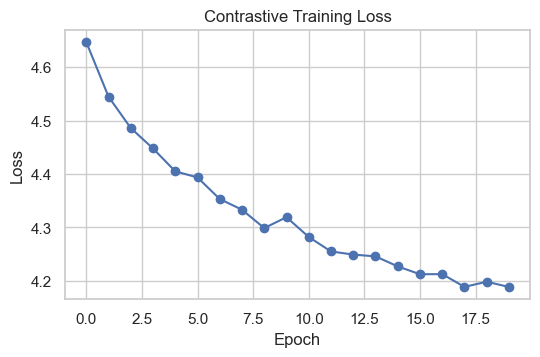

In [51]:
X_train = X_all[train_mask]
y_train_signal = y_signal_all[train_mask]

print('Training rows:', len(X_train))

encoder, loss_history = run_contrastive_training(
    X_train=X_train,
    y_train_signal=y_train_signal,
    embedding_dim=64,
    batch_size=128,
    epochs=20,
    lr=1e-3,
)

plt.figure(figsize=(6, 3.5))
plt.plot(loss_history, marker='o')
plt.title('Contrastive Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()


In [52]:
@torch.no_grad()
def embed_windows(model: Encoder1D, X: np.ndarray, batch_size: int = 512) -> np.ndarray:
    model.eval()
    out = []
    x_t = torch.tensor(X, dtype=torch.float32)
    for i in range(0, len(x_t), batch_size):
        xb = x_t[i:i+batch_size].unsqueeze(1).to(DEVICE)
        zb = model(xb).cpu().numpy()
        out.append(zb)
    return np.vstack(out)


Z = embed_windows(encoder, X_all)
print('Embedding shape:', Z.shape)

Embedding shape: (8144, 64)


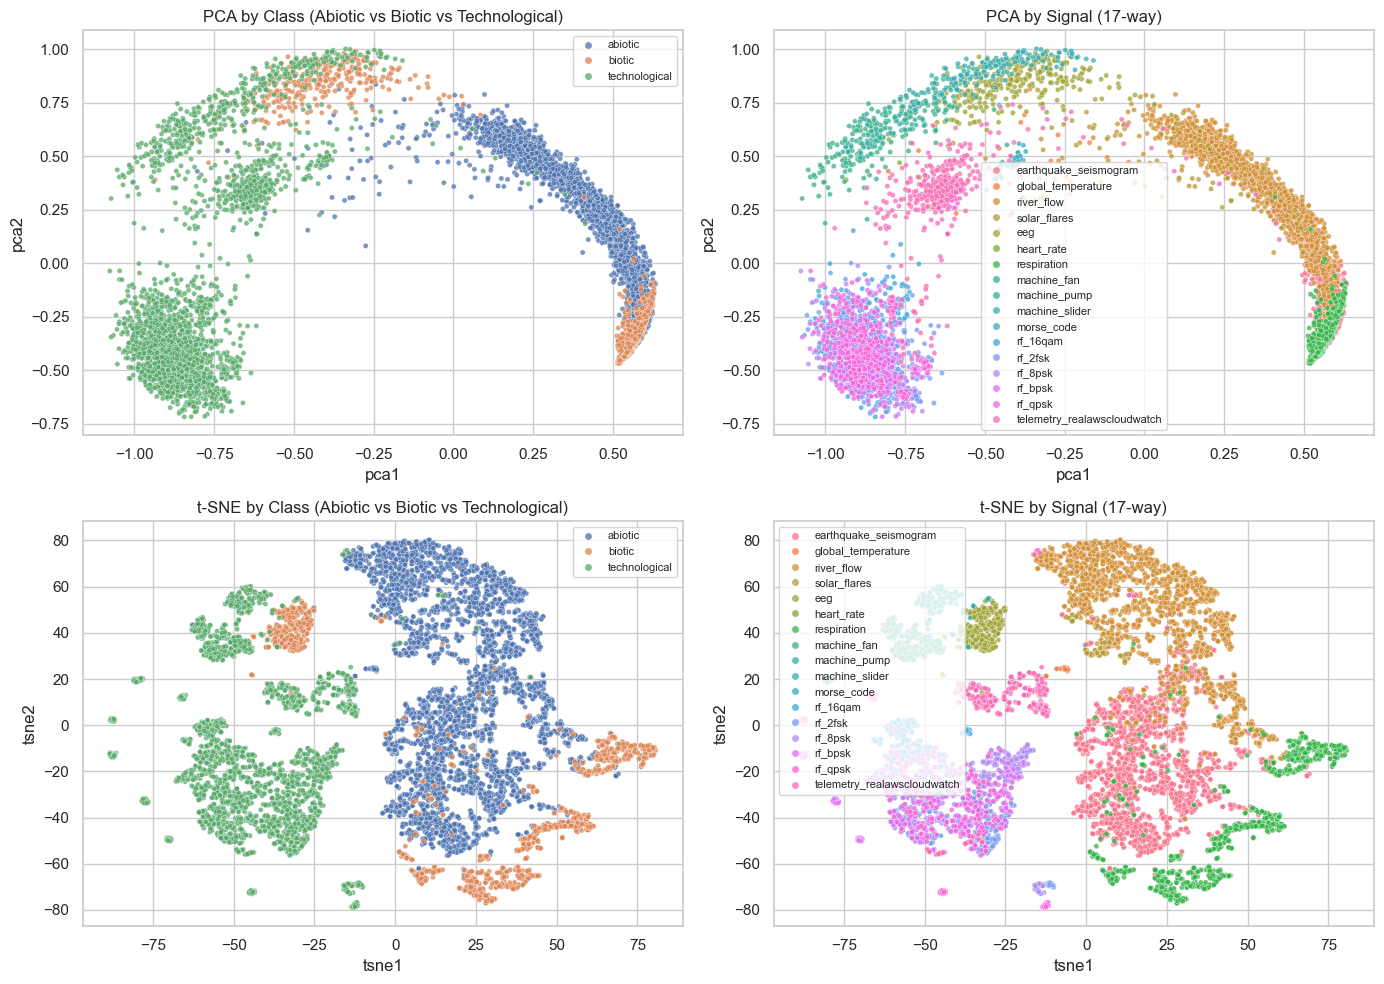

In [54]:
# PCA + t-SNE visualization for learned representation space.
plot_df = meta_all.copy()

pca = PCA(n_components=2, random_state=159)
Z_pca = pca.fit_transform(Z)
plot_df['pca1'] = Z_pca[:, 0]
plot_df['pca2'] = Z_pca[:, 1]

z_tsne = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=159).fit_transform(Z)
plot_df['tsne1'] = z_tsne[:, 0]
plot_df['tsne2'] = z_tsne[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=plot_df, x='pca1', y='pca2', hue='class_label', s=14, alpha=0.75, ax=axes[0, 0])
axes[0, 0].set_title('PCA by Class (Abiotic vs Biotic vs Technological)')

sns.scatterplot(data=plot_df, x='pca1', y='pca2', hue='signal_name', s=14, alpha=0.75, ax=axes[0, 1])
axes[0, 1].set_title('PCA by Signal (17-way)')

sns.scatterplot(data=plot_df, x='tsne1', y='tsne2', hue='class_label', s=14, alpha=0.75, ax=axes[1, 0])
axes[1, 0].set_title('t-SNE by Class (Abiotic vs Biotic vs Technological)')

sns.scatterplot(data=plot_df, x='tsne1', y='tsne2', hue='signal_name', s=14, alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title('t-SNE by Signal (17-way)')


for ax in axes.ravel():
    ax.legend(loc='best', fontsize=8, markerscale=1.4)

plt.tight_layout()
plt.show()

To add future sources (sleep cycle, internet traffic, GPS timing, telemetry):
1. Add a new `fetch_<signal>()` function returning `List[SignalRecord]`.
2. Register it in `SIGNAL_SPECS` with the class label.
3. Re-run `build_first_pass_dataset()`.
